In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
sns.set_theme(style="whitegrid")

here = Path.cwd()
ROOT = here if (here / "data" / "processed").exists() else here.parent
PROCESSED = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# load the master table
master = gpd.read_file(PROCESSED / "yield_master.gpkg")

# a clean version without the flagged rows (for comparison)
clean_only = master[master["qc_flag"] == ""].copy()

print("master:", len(master), "rows |", len(master.columns), "cols")
print("without flagged rows:", len(clean_only), "rows")
print()
print("rows per year:")
print(master["year"].value_counts().sort_index())

master: 1207 rows | 23 cols
without flagged rows: 1171 rows

rows per year:
year
2022     55
2023     60
2024    323
2025    769
Name: count, dtype: int64


YIELD (all 1207 rows, includes bad values):
count    1207.00
mean        9.41
std        21.93
min         0.00
25%         7.00
50%         8.20
75%        10.00
max       720.00

YIELD (1171 rows, flagged removed):
count    1171.00
mean        8.47
std         2.44
min         1.00
25%         7.00
50%         8.12
75%        10.00
max        20.00


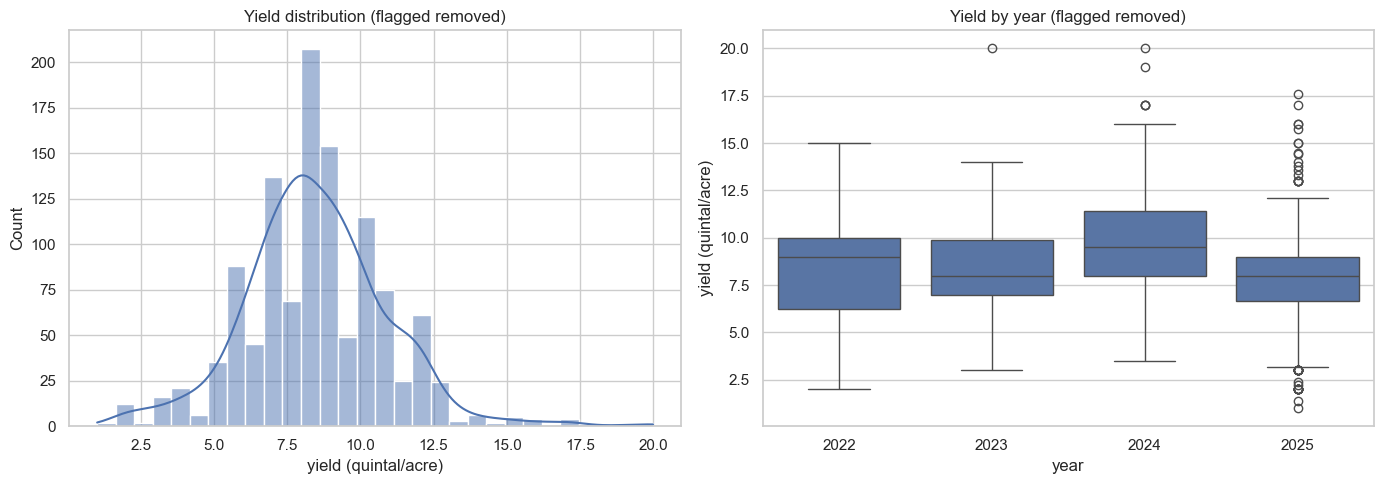

In [8]:
# ---- Yield summary, with vs without flagged rows ----
print("YIELD (all 1207 rows, includes bad values):")
print(master["crop_yield"].describe().round(2).to_string())
print()
print("YIELD (1171 rows, flagged removed):")
print(clean_only["crop_yield"].describe().round(2).to_string())

# ---- Plot 1: overall yield distribution (flagged removed, so the 720 doesn't ruin the scale) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(clean_only["crop_yield"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Yield distribution (flagged removed)")
axes[0].set_xlabel("yield (quintal/acre)")

# ---- Plot 2: yield by year ----
sns.boxplot(data=clean_only, x="year", y="crop_yield", ax=axes[1])
axes[1].set_title("Yield by year (flagged removed)")
axes[1].set_xlabel("year")
axes[1].set_ylabel("yield (quintal/acre)")

plt.tight_layout()
plt.savefig(FIGS / "01_yield_overview.png", dpi=120)
plt.show()

## Yield overview (the target)

first look at yield, the thing we predict. checking the numbers with and without the flagged rows, then plotting the shape and comparing years.

**why with vs without flagged:** the 2 broken yields (720, 260) blow up the stats. with them the std is 21.93 and max is 720. after removing the 36 flagged rows the mean is 8.47, std 2.44, max 20. that is the real yield.

**histogram:** yield is a gaussian shape centred around 8, most fields between 5 and 12. close to normal, which is good for modelling.

**yield by year:** 2022, 2023, 2025 sit around median 8. 2024 is a bit higher (median ~9.5), probably weather. so year is a useful variable to keep.

In [9]:
# ---- Yield by category columns ----
# For each category, show count and median yield per group (median is robust to outliers).

def yield_by(col, min_count=5):
    g = (clean_only.groupby(col)["crop_yield"]
         .agg(n="count", median_yield="median", mean_yield="mean")
         .round(2)
         .sort_values("median_yield", ascending=False))
    return g[g["n"] >= min_count]   # hide tiny groups (less than 5 fields)

print("=== YIELD by IRRIGATION ===")
print(yield_by("irrigation").to_string())
print()

print("=== YIELD by TALUKA ===")
print(yield_by("taluka").to_string())
print()

print("=== YIELD by VARIETY (top groups only) ===")
print(yield_by("variety", min_count=10).to_string())   # varieties with at least 10 fields

=== YIELD by IRRIGATION ===
                   n  median_yield  mean_yield
irrigation                                    
Drip             208           9.0        8.76
Flow/Protective  470           9.0        8.96
Rainfed          493           8.0        7.88

=== YIELD by TALUKA ===
                   n  median_yield  mean_yield
taluka                                        
Latur            412          9.00        8.91
Renapur          119          8.90        8.55
Nilanga          174          8.32        8.45
Chakur           121          8.05        8.19
Ausa             252          8.00        8.04
Shirur-Anantpal   85          8.00        7.95
Jalkot             7          7.00        8.66

=== YIELD by VARIETY (top groups only) ===
            n  median_yield  mean_yield
variety                                
kds 753    41         11.50       11.28
726        17         11.20       10.95
KDS 726    20          9.38        9.73
kds753     48          9.30        9.43
753  

## Yield by category (irrigation, taluka, variety)

Looking at how yield changes across the main text columns. Flagged rows are removed, and tiny groups (under 5 fields) are hidden. Using median yield since it is not thrown off by a few high values.

**Irrigation:** clear signal, and it makes sense. Irrigated fields (Drip and Flow/Protective) have a median yield of 9.0, while Rainfed fields sit at 8.0. So water gives about 1 quintal/acre more. Worth keeping as a feature.

**Taluka:** weak effect. Latur taluka is the highest at 9.0, and the rest sit between 8.0 and 8.9. The range is small, so location at the taluka level only matters a little. Keep it, but do not expect much from it.

**Variety:** could be useful, but the names are too messy to trust right now. The same variety is written many ways (KDS 753 shows up as "kds 753", "kds753", "753", "KDS753", "KDS 753"). This splits one real variety into several fake groups and makes the numbers unreliable (for example "kds 753" shows 11.5 but "KDS 753" shows 8.5, same seed). We need to clean and merge the variety names during feature prep before we can judge if variety affects yield.

Correlation of each soil variable with yield:
carbon        0.263
ec            0.263
ph            0.260
phosphorus    0.248
potassium     0.184
nitrogen      0.182

Reading guide: near 0 = no link, closer to +/-1 = stronger link


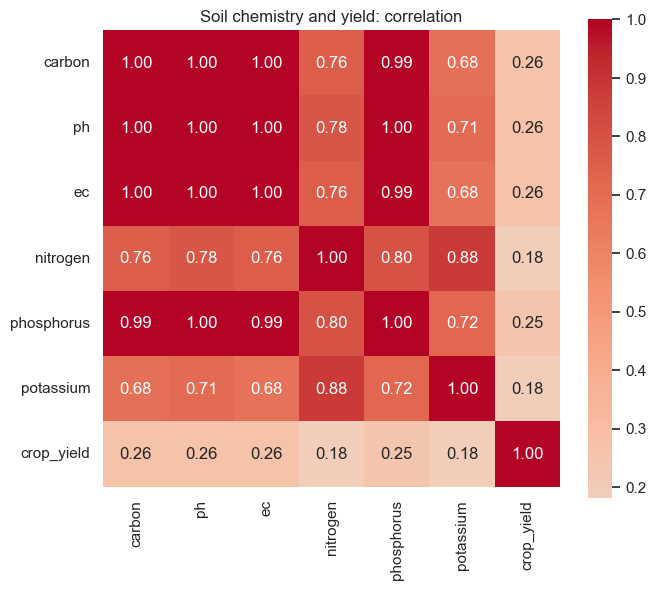

In [10]:
# ---- Soil chemistry vs yield (correlation) ----
soil_cols = ["carbon", "ph", "ec", "nitrogen", "phosphorus", "potassium"]

# correlation of each soil variable with yield
corr = clean_only[soil_cols + ["crop_yield"]].corr(numeric_only=True)["crop_yield"].drop("crop_yield")
print("Correlation of each soil variable with yield:")
print(corr.round(3).sort_values(ascending=False).to_string())
print()
print("Reading guide: near 0 = no link, closer to +/-1 = stronger link")

# heatmap so you can also see soil variables vs each other
plt.figure(figsize=(7, 6))
sns.heatmap(clean_only[soil_cols + ["crop_yield"]].corr(numeric_only=True),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Soil chemistry and yield: correlation")
plt.tight_layout()
plt.savefig(FIGS / "02_soil_yield_corr.png", dpi=120)
plt.show()

## Soil chemistry vs yield (and why we drop it)

Checked how the six soil chemistry columns (carbon, ph, ec, nitrogen, phosphorus, potassium) relate to yield. Two problems showed up.

**Fake correlations:** in the heatmap, carbon, ph and ec correlate at 1.00 with each other, and around 0.99 to 1.00 with phosphorus. Real soil variables are never this perfectly aligned, so this is a warning sign, not a real relationship.

**The cause:** about 80% of the soil chemistry is not real. 759 fields have every soil value set to -99, and 211 fields have every value set to 0. Both are placeholder codes for "not measured". Only around 237 fields (20%) have genuine soil readings. When 970 fields share the same placeholder values, the columns line up artificially and produce the fake 1.00 correlations.

**Decision:** drop all six soil chemistry columns. A feature that is 80% placeholder cannot be filled trustfully, and keeping it risks the model learning the placeholder pattern instead of real soil effects. The weak yield correlations seen here (~0.26) are computed on contaminated data and are not reliable.

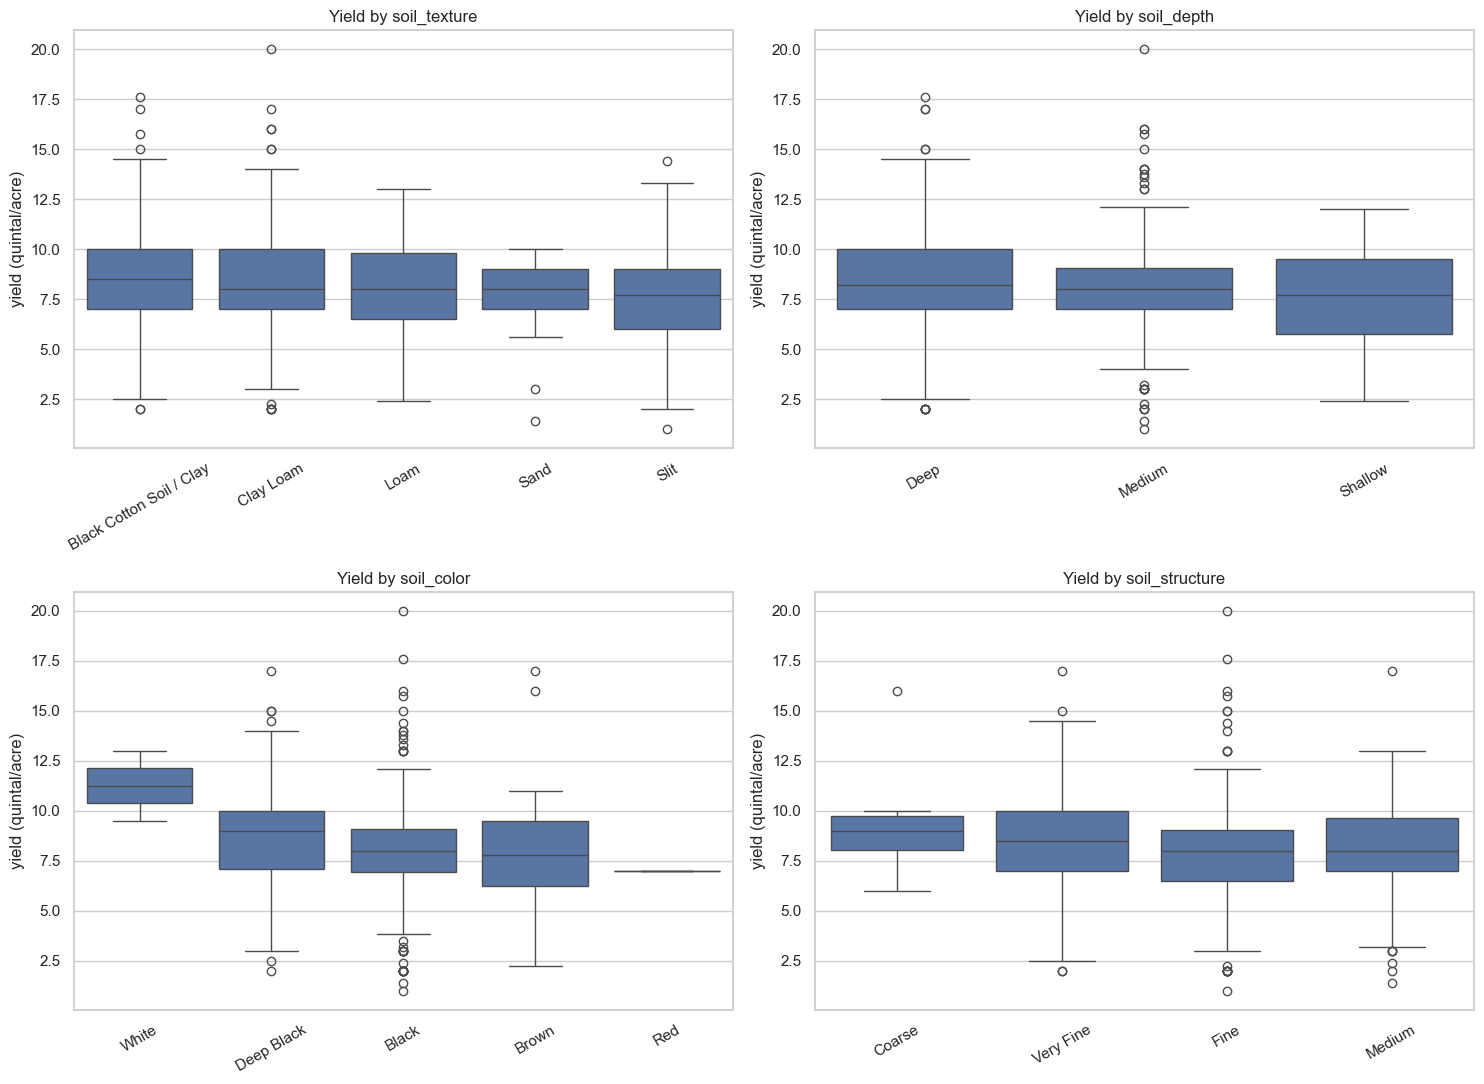

Median yield by soil_texture (real values only):
                            n  median
soil_texture                         
Black Cotton Soil / Clay  452    8.50
Clay Loam                 217    8.00
Loam                       43    8.00
Sand                       27    8.00
Slit                      206    7.74


In [11]:
# ---- Soil DESCRIPTION vs yield ----
# These are text categories, so we compare yield across categories with boxplots.
# First, clean the placeholder values (-, N/A) into real blanks for this view.
BAD = ["-", "N/A", "n/a", "NA", "na", ""]
desc = clean_only.copy()
for c in ["soil_color", "soil_structure", "soil_texture", "soil_depth"]:
    desc[c] = desc[c].astype(str).str.strip().replace(BAD, np.nan)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, col in zip(axes.ravel(), ["soil_texture", "soil_depth", "soil_color", "soil_structure"]):
    sub = desc[desc[col].notna()]
    order = sub.groupby(col)["crop_yield"].median().sort_values(ascending=False).index
    sns.boxplot(data=sub, x=col, y="crop_yield", order=order, ax=ax)
    ax.set_title(f"Yield by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("yield (quintal/acre)")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIGS / "03_soil_description_yield.png", dpi=120)
plt.show()

# also print median yield per soil texture (the most useful one)
print("Median yield by soil_texture (real values only):")
print(desc[desc["soil_texture"].notna()].groupby("soil_texture")["crop_yield"]
      .agg(n="count", median="median").round(2).sort_values("median", ascending=False).to_string())

## Soil description vs yield

The soil description columns (texture, depth, color, structure) are text categories, so we compare yield across each category with boxplots. Unlike the chemistry columns, these are 81% filled with real values, so they are worth checking properly.

**Soil texture:** weak but sensible effect. Black Cotton Soil / Clay is highest (median 8.5), while Silt is lowest (7.74). The gap between best and worst is under 1 quintal/acre. Clay holds water better so it yields a little more, sandy and silt soils drain faster and yield a little less.

**Soil depth:** almost flat. Deep 8.2, Medium 8.0, Shallow 7.7. Deeper soil is very slightly better, but the effect is tiny.

**Soil color:** the strongest of the four, mostly because of the White group (median 11.0), with the rest forming a mild gradient (Deep Black 9.0 down to Red 7.0). Caution: the White group has very few fields, so its high median may be a fluke and should not be over-trusted until group sizes are checked.

**Soil structure:** weakest. All categories sit around 8 to 9 with almost no difference.

**Takeaway:** the soil description columns relate to yield only weakly. They are worth keeping as minor supporting features, but they will not be the main drivers. The real yield signal should come from the satellite data (SAR and optical), which reflects the actual growing crop. During feature prep, small categories (like the White color group) should be checked and possibly merged into "Other" so the model does not chase noise.

C:\Users\Predator\AppData\Local\Temp\ipykernel_88580\3948927174.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  plot_gdf["pt"] = plot_gdf.geometry.centroid


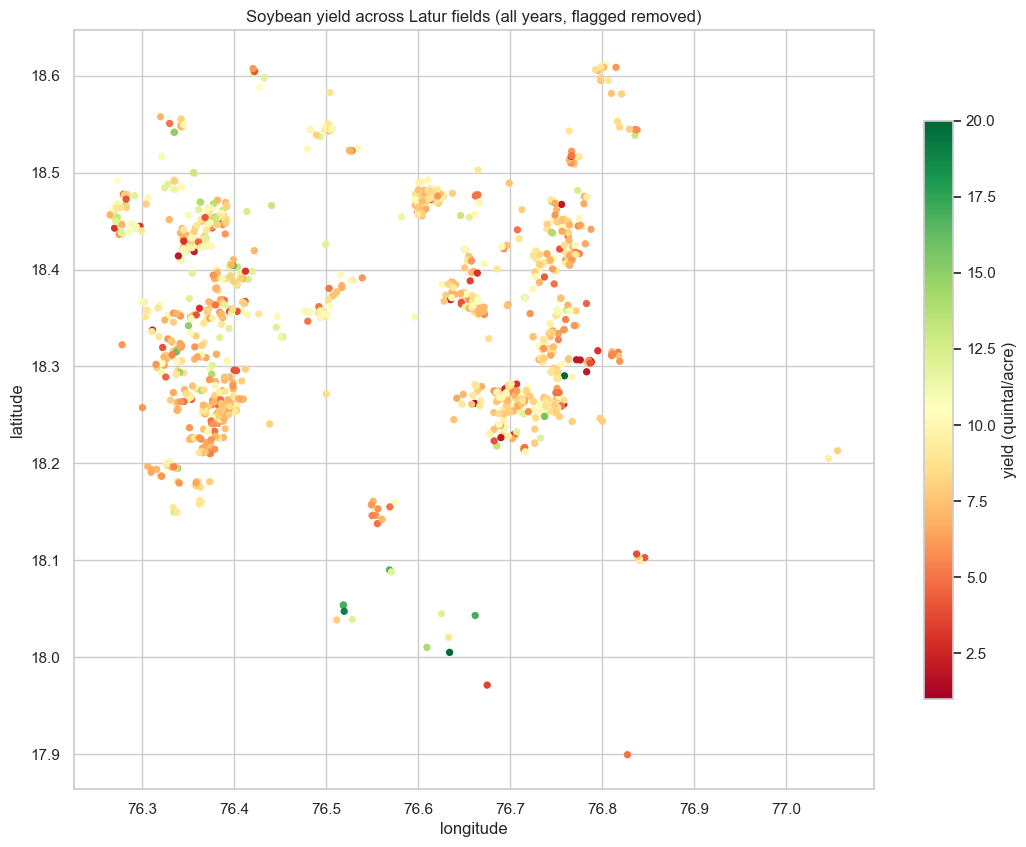

Highest-yield villages:
                n  median
village                  
Pimpri Amba     8   11.75
Chatgaon        5   11.00
Ganeshwadi     17   10.50
Masalga        13   10.00
Gondegaon      40   10.00
Chikhal Thana   8   10.00

Lowest-yield villages:
                    n  median
village                      
Sonavati           10     7.0
Sirshi (Hangarga)   7     7.0
Kambalga            6     6.2
Utka               10     6.0
Kalamgaon           7     5.6
Bevanal             8     2.5


In [12]:
# ---- Map: yield in space ----
# Color each field by its yield to see spatial patterns. Flagged rows excluded.

plot_gdf = clean_only.copy()
# use field centers (centroids) as points; clearer than tiny polygons at this scale
plot_gdf["pt"] = plot_gdf.geometry.centroid
pts = plot_gdf.set_geometry("pt")

fig, ax = plt.subplots(figsize=(11, 10))
pts.plot(
    ax=ax,
    column="crop_yield",
    cmap="RdYlGn",          # red = low yield, green = high yield
    markersize=18,
    legend=True,
    legend_kwds={"label": "yield (quintal/acre)", "shrink": 0.6},
)
ax.set_title("Soybean yield across Latur fields (all years, flagged removed)")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
plt.tight_layout()
plt.savefig(FIGS / "04_yield_map.png", dpi=120)
plt.show()

# quick spatial summary: yield by village (top and bottom, min 5 fields)
vil = (clean_only.groupby("village")["crop_yield"]
       .agg(n="count", median="median").round(2))
vil = vil[vil["n"] >= 5].sort_values("median", ascending=False)
print("Highest-yield villages:")
print(vil.head(6).to_string())
print("\nLowest-yield villages:")
print(vil.tail(6).to_string())

## Yield across space (the map)

Every field plotted at its location, colored by yield (red = low, green = high), flagged rows removed. This is the first spatial view of the data.

**Fields form clusters, not an even spread.** The survey sampled specific pockets (one large cluster around 76.3 to 76.4 longitude, another around 76.6 to 76.8, plus scattered fields to the south), matching the villages. So the model covers these pockets, not all of Latur evenly.

**No strong regional gradient.** Most fields are mid-range (yield 7 to 10), and colors are mixed within each cluster. High and low yield fields sit next to each other. This means location alone does not separate high from low yield, the differences come from field-level factors (the specific crop, water, and soil of each field). This supports using per-field satellite features as the main signal source, since the pattern is local rather than regional.

**Village effect is real but modest.** Top villages reach a median of 10 to 11.75, bottom villages 2.5 to 7.0, so village roughly doubles yield between best and worst. But the extreme villages have few fields (5 to 8 each), so those medians are unstable and should not be over-read (e.g. Bevanal at 2.5 with only 8 fields).

**Implication for train/test split.** Because fields cluster tightly and about 90 plots overlap across years, a random split would place near-identical neighboring fields in both train and test, leaking information. The split must be done by location (village or spatial block) so whole clusters stay on one side.

In [13]:
# ---- Variety text messiness ----
# The same variety is written many ways. Show the raw spellings and counts.

print("Raw variety values (as stored):", clean_only["variety"].nunique(), "distinct spellings")
print()
print(clean_only["variety"].value_counts(dropna=False).to_string())
print()

# quick preview of what a simple standardization would do:
# lowercase, remove spaces, so "KDS 753" / "kds753" / "Kds 753" collapse together
norm = (clean_only["variety"].astype(str)
        .str.lower().str.replace(" ", "", regex=False).str.strip())
print("After simple normalize (lowercase + remove spaces):", norm.nunique(), "distinct")
print()
print(norm.value_counts().head(20).to_string())

Raw variety values (as stored): 72 distinct spellings

variety
KDS 753           243
DS 228            214
KDS 992            97
753                85
MAUS 612           77
JS 335             58
kds753             48
228                43
kds 753            41
NaN                34
335                32
KDS753             24
KDS 726            20
DS228              18
726                17
KDS 725            17
AMS 1001           11
612                10
MAUS 162            6
kds726              4
71                  3
KDS-726             3
Kds 753             3
ds 228              3
maus 612            3
केडीएस ९९२          3
MAUS-71             2
Ds228               2
Kds753              2
754                 2
केडीएस ७५३          2
MAUS 158            2
js 335              2
KDS-71              1
Kds-726             1
3344                1
218                 1
kds500              1
KDS-726,DS-228      1
maus-71             1
late                1
KDS-753             1
2            

## Variety text messiness

The variety column has 72 distinct spellings, but these map to only about 12 real varieties. The same seed is written many ways, for example KDS 753 appears as "KDS 753", "753", "kds753", "kds 753", "KDS753", "KDS-753", and a few typos like "kda753" and "KSS753".

A simple normalize (lowercase and remove spaces) already helps, cutting 72 spellings to 53 and merging the big groups: kds753 (361), ds228 (239), kds992 (98), maus612 (81), js335 (60).

But simple normalize is not enough, three problems remain:
1. Bare numbers stay separate from full names ("753" vs "kds753", "228" vs "ds228"), even though they are the same variety.
2. Hyphens and typos block merging ("kds-726" vs "kds726", plus errors like "kda753", "726kds").
3. A few entries are in Marathi script (केडीएस ९९२ = KDS 992, केडीएस ७५३ = KDS 753) and need mapping to English.

**Plan (feature prep, not now):** build a variety lookup that collapses all spellings, bare numbers, hyphens, typos, and Marathi into one clean label each. This should give about 10 to 12 real varieties, with KDS 753 and DS 228 dominating (~600 fields, roughly half the data). Tiny one-off or junk entries ("late", "3344", "2.11", single fields) get grouped into "Other". Variety is worth keeping, but only after this standardization.

In [14]:
# ---- Final missing-data summary (true picture, placeholders counted as missing) ----
BAD_TEXT = ["-", "N/A", "n/a", "NA", "na", "", "None", "none"]

audit = clean_only.copy()

# soil chemistry: -99 and 0 are placeholders, count them as missing
chem = ["carbon", "ph", "ec", "nitrogen", "phosphorus", "potassium"]
for c in chem:
    audit[c] = audit[c].replace([-99, 0], np.nan)

# soil description: "-" and "N/A" are placeholders
desc = ["soil_color", "soil_structure", "soil_texture", "soil_depth"]
for c in desc:
    audit[c] = audit[c].astype(str).str.strip().replace(BAD_TEXT, np.nan)

N = len(audit)
rows = []
for c in audit.columns:
    if c in ("geometry", "qc_flag"):
        continue
    miss = audit[c].isna().sum()
    rows.append({"column": c, "missing": int(miss), "missing_%": round(100 * miss / N, 1)})

summary = pd.DataFrame(rows).sort_values("missing_%", ascending=False)
print(f"True missing-data picture (n = {N}, placeholders counted as missing):")
print(summary.to_string(index=False))

True missing-data picture (n = 1171, placeholders counted as missing):
        column  missing  missing_%
            ec      947       80.9
            ph      942       80.4
      nitrogen      942       80.4
        carbon      942       80.4
     potassium      942       80.4
    phosphorus      942       80.4
  soil_texture      226       19.3
soil_structure      226       19.3
    soil_color      226       19.3
    soil_depth      226       19.3
   sowing_date       34        2.9
       variety       34        2.9
           uid        0        0.0
          crop        0        0.0
       village        0        0.0
        taluka        0        0.0
          year        0        0.0
  harvest_date        0        0.0
    area_acres        0        0.0
    irrigation        0        0.0
    crop_yield        0        0.0


## Inspecting the high yields (>20 quintal/acre)

Eight fields have yields above 20 quintal/acre and were flagged as yield_suspect. Before deciding to keep or drop, we inspect them against the rest of the data.

For context, the other fields top out at 20 (99th percentile is 15, 95th is 12), so these eight sit at the very top of the range. They are: 47, 38, 32, 32, 28, 24, 22, 20.3, mostly from 2024 and mostly irrigated (Flow/Protective or Drip).

We checked whether the high values come from a tiny-area miscalculation, but the areas are normal (1.6 to 5.3 acres), so the high number is the yield itself, not an area artefact.

**Decision: keep all eight.** They are above the 99th percentile but not physically impossible, and their fields have normal area and irrigation. 

In [15]:
# ---- Inspect the high yields (>20 quintal/acre) ----
# Look at the master (includes flagged) to see the high yields in their original form.
high = master[(master["crop_yield"] > 20) & (master["crop_yield"] <= 100)].sort_values("crop_yield", ascending=False)

print("High-yield fields (>20 quintal/acre):", len(high))
print(high[["year", "village", "crop_yield", "variety", "irrigation", "area_acres"]].round(2).to_string(index=False))
print()

normal = master[(master["crop_yield"] > 0) & (master["crop_yield"] <= 20)]["crop_yield"]
print("For reference, the other fields:")
print(f"  95th percentile: {normal.quantile(0.95):.1f} | 99th: {normal.quantile(0.99):.1f} | max: {normal.max():.1f}")
print()


High-yield fields (>20 quintal/acre): 8
 year     village  crop_yield variety      irrigation  area_acres
 2024 Ganjankheda        47.0     753 Flow/Protective        5.28
 2024     Killari        38.0     228            Drip        3.02
 2024     Mangrul        32.0     228 Flow/Protective        2.87
 2024 Ganjankheda        32.0     753 Flow/Protective        3.28
 2024     Harwadi        28.0     753 Flow/Protective        4.06
 2025       Bheta        24.0  JS 335 Flow/Protective        1.62
 2024     Killari        22.0     753         Rainfed        2.64
 2025       Bheta        20.3  JS 335 Flow/Protective        2.06

For reference, the other fields:
  95th percentile: 12.0 | 99th: 15.0 | max: 20.0



## EDA summary and column decisions

Final picture after treating all placeholder codes (-99, 0, "N/A", "-") as missing. This is the bridge into feature engineering.

### Missing-data conclusion
Two columns groups are affected. Soil chemistry is about 80% placeholder and unusable. Soil description is about 19% missing but otherwise real. Everything else is complete or nearly so (variety and sowing date about 3%).

### Column decisions

**Drop (unusable, ~80% placeholder):**
carbon, ph, ec, nitrogen, phosphorus, potassium. These are coded -99 or 0 for most fields, cannot be filled trustfully, and produced fake correlations. Dropped.

**Keep, fill small gaps later (~19% missing):**
soil_color, soil_structure, soil_texture, soil_depth. 81% real with meaningful categories and a weak but valid link to yield. Fill the gap with "Unknown" (or village-typical) during feature prep.

**Keep, needs cleanup then fill (~3% missing):**
- variety: standardize the 72 spellings to about 12 real varieties first, then fill 34 blanks with "Unknown".
- sowing_date: fill 34 blanks with the village-median sowing date, then convert to features (day-of-season, and crop duration using harvest_date).

**Keep, ready to use (0% missing):**
crop_yield (target), area_acres, irrigation, year, village, taluka, harvest_date. Note: crop is a single value ("Soyabean") so it is a label not a feature, and uid is an identifier.

### Key conclusions from EDA
1. Yield is clean and near-normal (mean 8.47, std 2.44 after flag removal), good for regression.
2. Yield differences are driven by local field-level conditions, not broad region (the map shows mixed high and low yield within each cluster). Per-field features are the right approach.
3. Irrigation is the clearest categorical signal (~1 quintal/acre uplift). Soil description, variety, taluka are weak helpers.
4. This ground-truth file provides the target and weak helper features only. The main predictive signal must come from satellite data (SAR and optical), extracted per field polygon.

### Carried-forward rules for modelling
- Exclude the 36 QC-flagged records from analysis and modelling.
- Apply all fixes (drop soil chemistry, blank bad dates, handle bad area/geometry, drop 3 impossible yields) in one dedicated step that writes an analysis-ready file, leaving the master untouched.
- Use a spatial train/test split (by village or spatial block), not a random split, because fields cluster tightly and about 90 plots overlap across years.


In [17]:
%pip install contextily

  Using cached contextily-1.7.1-py3-none-any.whl.metadata (3.1 kB)
  Using cached geopy-2.5.0-py3-none-any.whl.metadata (7.1 kB)
  Using cached mercantile-1.2.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached geographiclib-2.1-py3-none-any.whl.metadata (1.6 kB)
Using cached contextily-1.7.1-py3-none-any.whl (18 kB)
Using cached geopy-2.5.0-py3-none-any.whl (114 kB)
Using cached geographiclib-2.1-py3-none-any.whl (40 kB)
Using cached mercantile-1.2.1-py3-none-any.whl (14 kB)

   -------------------- ------------------- 2/4 [geopy]
   -------------------- ------------------- 2/4 [geopy]
   ---------------------------------------- 4/4 [contextily]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
%pip install geopy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
from pathlib import Path
import time
import pandas as pd
from geopy.geocoders import Nominatim

ROOT = Path(r"F:\THESIS\mtech_thesis_crop_yield_estimation")

# taluka headquarters towns for the talukas in your data
towns = ["Latur", "Ausa", "Nilanga", "Renapur", "Chakur", "Shirur Anantpal", "Jalkot", "Deoni"]
geo = Nominatim(user_agent="thesis-latur-map-josaiah")

rows = []
for t in towns:
    loc = geo.geocode(f"{t}, Latur, Maharashtra, India", country_codes="in", featuretype="settlement")
    rows.append({
        "town": t,
        "lat": round(loc.latitude, 4) if loc else None,
        "lon": round(loc.longitude, 4) if loc else None,
        "found_as": loc.address[:70] if loc else "NOT FOUND",
    })
    time.sleep(1.1)   # OpenStreetMap allows 1 request per second

towns_df = pd.DataFrame(rows)
print(towns_df.to_string(index=False))
towns_df.to_csv(ROOT / "data" / "processed" / "latur_taluka_towns.csv", index=False)

           town     lat     lon                                           found_as
          Latur 18.3982 76.5626                  Latur, Maharashtra, 413512, India
           Ausa 18.2510 76.5010            Ausa, Latur, Maharashtra, 413520, India
        Nilanga 18.0838 76.7992                 Nilanga, Latur, Maharashtra, India
        Renapur 18.5264 76.5968         Renapur, Latur, Maharashtra, 413527, India
         Chakur 18.5175 76.8766          Chakur, Latur, Maharashtra, 413513, India
Shirur Anantpal 18.3286 76.8186 Shirur-Anantpal, Latur, Maharashtra, 413544, India
         Jalkot 18.6291 77.1783          Jalkot, Latur, Maharashtra, 413546, India
          Deoni 18.2644 77.0821           Deoni, Latur, Maharashtra, 413519, India


In [25]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"F:\THESIS\mtech_thesis_crop_yield_estimation")

# verified taluka headquarters coordinates (checked against GeoNames / Wikipedia)
towns_df = pd.DataFrame([
    {"town": "Latur",           "lat": 18.3969, "lon": 76.5678, "source": "GeoNames"},
    {"town": "Ausa",            "lat": 18.2472, "lon": 76.4992, "source": "GeoNames"},
    {"town": "Renapur",         "lat": 18.5264, "lon": 76.5975, "source": "GeoNames"},
    {"town": "Chakur",          "lat": 18.5058, "lon": 76.8731, "source": "GeoNames"},
    {"town": "Nilanga",         "lat": 18.1167, "lon": 76.7528, "source": "GeoNames"},
    {"town": "Shirur Anantpal", "lat": 18.3386, "lon": 76.8400, "source": "Wikipedia"},
    {"town": "Deoni",           "lat": 18.2639, "lon": 77.0822, "source": "Wikipedia"},
    {"town": "Jalkot",          "lat": 18.6292, "lon": 77.1811, "source": "GeoNames"},
])
towns_df.to_csv(ROOT / "data" / "processed" / "latur_taluka_towns.csv", index=False)
print(towns_df.to_string(index=False))

           town     lat     lon    source
          Latur 18.3969 76.5678  GeoNames
           Ausa 18.2472 76.4992  GeoNames
        Renapur 18.5264 76.5975  GeoNames
         Chakur 18.5058 76.8731  GeoNames
        Nilanga 18.1167 76.7528  GeoNames
Shirur Anantpal 18.3386 76.8400 Wikipedia
          Deoni 18.2639 77.0822 Wikipedia
         Jalkot 18.6292 77.1811  GeoNames


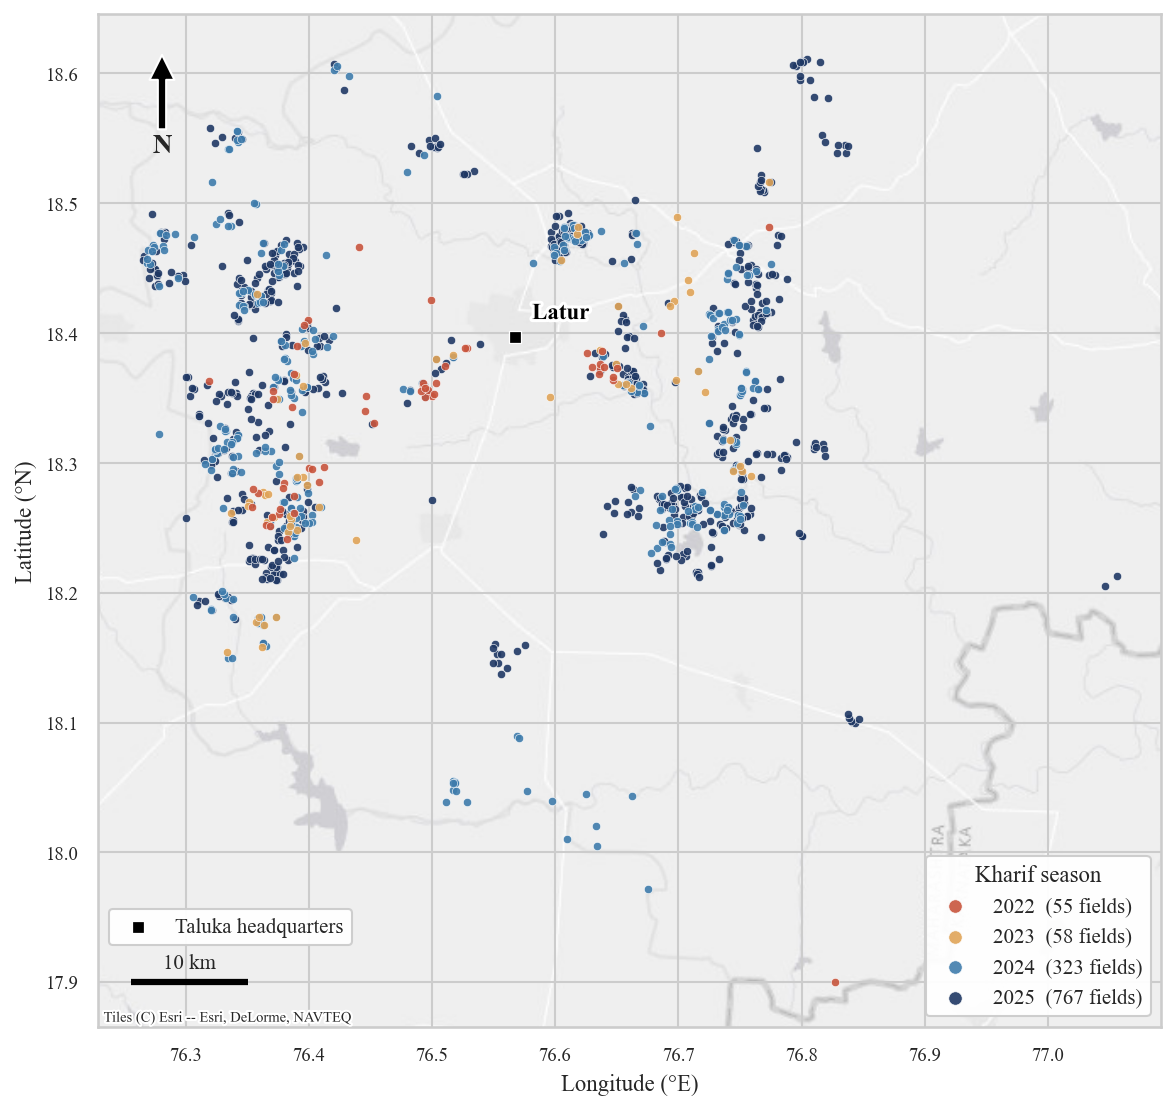

saved: F:\THESIS\mtech_thesis_crop_yield_estimation\reports\figures\09_field_locations_map.png
towns outside the map extent (not shown): []


In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import contextily as cx

ROOT = Path(r"F:\THESIS\mtech_thesis_crop_yield_estimation")
FIGS = ROOT / "reports" / "figures"

# load fields, drop the one with no polygon
fields = gpd.read_file(ROOT / "data" / "processed" / "yield_analysis_ready.gpkg")
fields = fields[fields.geometry.notna() & ~fields.geometry.is_empty].copy()

# field centres in Web Mercator (EPSG:3857), the same projection as the basemap tiles
centres = fields.to_crs(32643).geometry.centroid.to_crs(3857)
fields["x"], fields["y"] = centres.x.values, centres.y.values

# helpers: lat/long degrees -> Web Mercator metres
R = 6378137.0
lon2x = lambda lon: np.radians(lon) * R
lat2y = lambda lat: R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))

# checked taluka headquarters locations (from the geocoding step)
towns = pd.read_csv(ROOT / "data" / "processed" / "latur_taluka_towns.csv").dropna()
towns = towns[towns["town"] == "Latur"]   # keep only Latur city as the reference point
towns["x"], towns["y"] = lon2x(towns["lon"]), lat2y(towns["lat"])

colors = {2022: "#C8553D", 2023: "#E0A458", 2024: "#3F7CAC", 2025: "#1F3864"}
plt.rcParams["font.family"] = "Times New Roman"

fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

# fields: big years first so the small years stay visible on top
for yr in [2025, 2024, 2023, 2022]:
    s = fields[fields["year"] == yr]
    ax.scatter(s["x"], s["y"], s=16, c=colors[yr], alpha=0.9,
               edgecolors="white", linewidths=0.3, zorder=3,
               label=f"{yr}  ({len(s)} fields)")

# map extent with a 4 km margin
pad = 4000
xmin, xmax = fields["x"].min() - pad, fields["x"].max() + pad
ymin, ymax = fields["y"].min() - pad, fields["y"].max() + pad
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

# light grey background (Esri, no API key needed)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, zoom=10, attribution_size=7)

# taluka headquarters: marker + label with a white halo
halo = [pe.withStroke(linewidth=3, foreground="white")]
skipped = []
for _, t in towns.iterrows():
    if not (xmin <= t["x"] <= xmax and ymin <= t["y"] <= ymax):
        skipped.append(t["town"])
        continue
    ax.scatter(t["x"], t["y"], marker="s", s=28, c="black", edgecolors="white", linewidths=0.6, zorder=6)
    near_right_edge = t["x"] > xmax - 15000
    ax.text(t["x"] + (-1500 if near_right_edge else 1500), t["y"] + 1200, t["town"],
            ha="right" if near_right_edge else "left", va="bottom",
            fontsize=11, fontweight="bold", color="black", zorder=7, path_effects=halo)

# lat/long tick labels every 0.1 degree
lons = np.round(np.arange(76.2, 77.15, 0.1), 1)
lats = np.round(np.arange(17.8, 18.75, 0.1), 1)
xt, yt = lon2x(lons), lat2y(lats)
kx, ky = (xt >= xmin) & (xt <= xmax), (yt >= ymin) & (yt <= ymax)
ax.set_xticks(xt[kx]); ax.set_xticklabels([f"{v:.1f}" for v in lons[kx]])
ax.set_yticks(yt[ky]); ax.set_yticklabels([f"{v:.1f}" for v in lats[ky]])

# scale bar: 10 km (Web Mercator stretches distances by 1/cos(latitude))
lat_mid = np.degrees(2 * np.arctan(np.exp(((ymin + ymax) / 2) / R)) - np.pi / 2)
bar = 10000 / np.cos(np.radians(lat_mid))
x0, y0 = xmin + 3000, ymin + 4000
ax.plot([x0, x0 + bar], [y0, y0], color="black", lw=3, solid_capstyle="butt", zorder=5)
ax.text(x0 + bar / 2, y0 + 1300, "10 km", ha="center", fontsize=10, zorder=5)

# north arrow
ax.annotate("N", xy=(0.06, 0.96), xytext=(0.06, 0.87), xycoords="axes fraction",
            ha="center", va="center", fontsize=13, fontweight="bold",
            arrowprops=dict(facecolor="black", width=4, headwidth=12))

# legends: seasons (lower right) and taluka HQ (lower left, above the scale bar)
h, l = ax.get_legend_handles_labels()
leg1 = ax.legend(h[::-1], l[::-1], title="Kharif season", loc="lower right",
                 fontsize=10, title_fontsize=11, framealpha=0.95, markerscale=1.6)
ax.add_artist(leg1)
hq = ax.scatter([], [], marker="s", s=28, c="black", edgecolors="white", linewidths=0.6)
ax.legend([hq], ["Taluka headquarters"], loc="lower left", bbox_to_anchor=(0.0, 0.07),
          fontsize=10, framealpha=0.95)

ax.set_xlabel("Longitude (°E)", fontsize=11)
ax.set_ylabel("Latitude (°N)", fontsize=11)
ax.tick_params(labelsize=9)

plt.tight_layout()
out = FIGS / "09_field_locations_map.png"
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("saved:", out)
print("towns outside the map extent (not shown):", skipped)